# 12 - Exposição: população, edifícios, estradas e equipamentos

| | |
|---|---|
| **Tarefa do plano** | Dados de entrada do motor de alertas (P2, necessários na semana 4) |
| **Variáveis (Parte I)** | #48 população, #49 edifícios, #50 estradas, escolas, centros de saúde |
| **Fonte** | WorldPop e Google Open Buildings v3 via Earth Engine; OpenStreetMap via Overpass (osmnx) |
| **Saída** | `data/raw/exposure/` |

Todas as camadas estão limitadas à AOI das imagens.

Correr primeiro `00_setup_and_authentication` e `01_study_area_aoi`. Todos os
downloads podem ser retomados: os ficheiros que já existem são saltados, e cada
ficheiro fica registado em `data/metadata/download_manifest.csv`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import ee
import pandas as pd
import matplotlib.pyplot as plt

from ete import config, datasets, gee, series
from ete import grid as G

cfg = config.load_config()
gee.init(cfg)

aoi = G.load_aoi(cfg)                       # AOI das imagens (EPSG:4326)
region = gee.ee_geometry(aoi)
grid30 = G.load_grid(cfg)                   # grelha do projeto a 30 m (EPSG:32736)
grid10 = G.load_grid(cfg, 10)               # grelha a 10 m, encaixada na de 30 m
climate_bounds = tuple(G.load_aoi(cfg, "aoi_climate").total_bounds)   # O, S, E, N
MASK = gee.ee_geometry(G.imagery_mask(cfg))  # distrito + margem: fora daqui as imagens mensais ficam sem dados

import geopandas as gpd
ex = cfg["datasets"]["exposure"]

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


## 1. População (WorldPop, grelha nativa de ~100 m)

Mantida na grelha nativa lat/lon para que a contagem de pessoas por píxel não
seja alterada pela reamostragem.

exists     worldpop_2020_marracuene_native.tif
pessoas dentro da AOI das imagens: 1,477,608


<Axes: title={'center': 'worldpop_2020_marracuene_native.tif\npopulation'}>

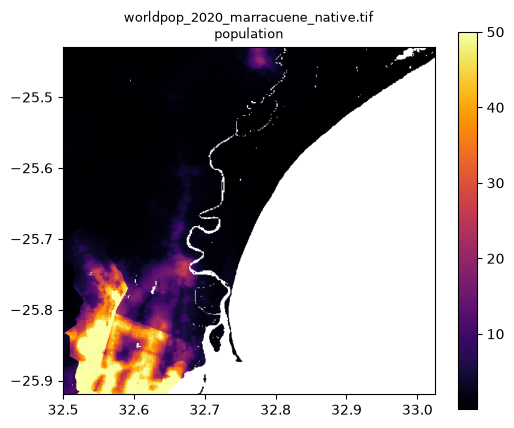

In [2]:
pop = (ee.ImageCollection(ex["worldpop"])
       .filter(ee.Filter.eq("country", "MOZ")).filter(ee.Filter.eq("year", ex["worldpop_year"]))
       .first().select("population"))
pop_grid = G.native_latlon_grid(pop.projection().getInfo()["transform"], tuple(aoi.total_bounds))
pop_file = gee.download_static(cfg, f"worldpop_{ex['worldpop_year']}", ex["worldpop"], pop, ["population"], pop_grid, "population")

import rasterio
with rasterio.open(pop_file) as src:
    print(f"pessoas dentro da AOI das imagens: {src.read(1, masked=True).sum():,.0f}")
series.show_raster(pop_file, cmap="inferno", vmax=50)

## 2. Edifícios (Google Open Buildings v3)

Descarregados em mosaicos (a tabela é grande) e depois unidos; os duplicados nas
fronteiras dos mosaicos são removidos com o plus code do edifício. Só se pedem os
mosaicos que tocam no distrito + margem. Se o servidor recusar um mosaico por ser
demasiado pesado, ele é dividido em quatro e pedido de novo; a célula pode ser
interrompida e retomada.

In [3]:
import numpy as np
from tqdm.auto import tqdm

buildings_file = config.path(cfg, "buildings", f"open_buildings_{cfg['project']['aoi_name']}.gpkg")
if not buildings_file.exists():
    from shapely.geometry import box
    fc = ee.FeatureCollection(ex["open_buildings"]).filter(ee.Filter.gte("confidence", ex["open_buildings_min_confidence"]))
    mask_polygon = G.imagery_mask(cfg).union_all()                      # distrito + margem
    inside = lambda w, s, e, n: box(w, s, e, n).intersects(mask_polygon)   # salta mar e cantos fora do distrito
    w, s, e, n = aoi.total_bounds
    # mosaicos de cerca de 0,025 graus (2,5 km): pedidos pequenos, a que o servidor responde em segundos
    nx, ny = int(np.ceil((e - w) / 0.025)), int(np.ceil((n - s) / 0.025))
    xs, ys = np.linspace(w, e, nx + 1), np.linspace(s, n, ny + 1)
    tiles_dir = config.path(cfg, "buildings", "tiles")
    files = []
    for i in tqdm(range(nx), desc="edifícios"):
        for j in range(ny):
            # um mosaico cujo pedido falha é dividido em quatro mais pequenos, automaticamente
            files += gee.download_vector_tiled(fc, (xs[i], ys[j], xs[i + 1], ys[j + 1]), tiles_dir,
                                               keep=inside, name=f"tile_{i:02d}_{j:02d}")
    parts = [part for part in (gpd.read_file(f) for f in files) if len(part)]
    buildings = gpd.GeoDataFrame(pd.concat(parts), crs=4326).drop_duplicates("full_plus_code")
    buildings = buildings[buildings.intersects(mask_polygon)][["full_plus_code", "confidence", "area_in_meters", "geometry"]]
    buildings.to_file(buildings_file, driver="GPKG")
    config.log_manifest(cfg, dataset="open_buildings", source_id=ex["open_buildings"], period="static",
                        status="downloaded", n_images=len(buildings), file=buildings_file, crs="EPSG:4326")
buildings = gpd.read_file(buildings_file)
print(f"{len(buildings):,} edifícios com confiança >= {ex['open_buildings_min_confidence']}")

499,408 edifícios com confiança >= 0.7


## 3. Estradas, escolas e unidades de saúde (OpenStreetMap)

In [ ]:
import osmnx as ox

polygon = aoi.union_all()
layers = {
    "roads": {"highway": ["motorway", "trunk", "primary", "secondary", "tertiary", "unclassified", "residential", "track"]},
    "schools": {"amenity": ["school", "kindergarten", "college", "university"]},
    "health": {"amenity": ["hospital", "clinic", "doctors", "pharmacy"], "healthcare": True},
}
for layer, tags in layers.items():
    out = config.path(cfg, "osm", f"osm_{layer}_{cfg['project']['aoi_name']}.gpkg")
    if not out.exists():
        feats = ox.features_from_polygon(polygon, tags).reset_index()
        keep = [c for c in ["id", "name", "highway", "amenity", "healthcare", "surface", "geometry"] if c in feats.columns]
        feats = feats[keep]
        for col in feats.columns.drop("geometry"):
            feats[col] = feats[col].astype(str)
        feats.to_file(out, driver="GPKG")
        config.log_manifest(cfg, dataset=f"osm_{layer}", source_id="OpenStreetMap (Overpass)", period=str(pd.Timestamp.today().date()),
                            status="downloaded", n_images=len(feats), file=out, crs="EPSG:4326")
    print(layer, len(gpd.read_file(out)), "elementos")

roads 34443 elementos
schools 130 elementos
health 66 elementos


: 

A cobertura do OpenStreetMap para escolas e centros de saúde nas zonas rurais de
Moçambique é incompleta: tratar estas camadas como um limite inferior e dizê-lo
na plataforma.